In [4]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt 
import pandas as pd, numpy as np, matplotlib.pyplot as plt

plt.rcParams["figure.figsize"]=(9,4); plt.rcParams["axes.grid"]=True 
CSV = "ejercicio_fases_analitica_farmacia.csv"  # <- usa este nombre exacto 
df = pd.read_csv(CSV)  
# tipos y fechas 
df["fecha_semana"] = pd.to_datetime(df["fecha_semana"], errors="coerce") 
df["semana"] = df["semana"].astype(int)

# features útiles 
df["tasa_venta"] = df["unidades_vendidas"] / df["stock_inicio_sem"] 
df.head(10)

,semana,fecha_semana,producto,precio_unit,promo,stock_inicio_sem,unidades_vendidas,stock_fin_sem,stockout_sem,lluvia_mm_sem,prox_feriado,competencia_precio,lead_time_dias,riesgo_quiebre_prox_sem,tasa_venta
0,1,2024-01-01,Paracetamol_500mg,1.25,0,103,21,82,0,24.6,1,1.24,5,0,0.203883
1,1,2024-01-01,Ibuprofeno_400mg,1.50,0,58,32,26,0,24.6,1,1.58,5,0,0.551724
2,1,2024-01-01,Antigripal,1.93,1,58,24,34,0,24.6,1,1.93,6,0,0.413793
3,1,2024-01-01,Vitaminas_C,2.97,0,62,22,40,0,24.6,1,3.05,4,0,0.354839
4,1,2024-01-01,Jarabe_Tos,3.59,0,89,15,74,0,24.6,1,3.74,9,0,0.168539
5,1,2024-01-01,Antiacido,2.10,1,59,16,43,0,24.6,1,2.23,4,0,0.271186
6,1,2024-01-01,Antihistaminico,2.68,0,96,11,85,0,24.6,1,2.80,3,0,0.114583
7,1,2024-01-01,Suero_Oral,0.91,1,85,23,62,0,24.6,1,0.94,6,0,0.270588
8,1,2024-01-01,Alcohol_Gel,1.83,0,95,11,84,0,24.6,1,1.87,4,0,0.115789
9,1,2024-01-01,Bloqueador_Solar,6.41,0,117,7,110,0,24.6,1,6.79,2,0,0.059829


producto
Ibuprofeno_400mg     3.85%
Paracetamol_500mg    3.85%
Alcohol_Gel          0.00%
Antiacido            0.00%
Antigripal           0.00%
Antihistaminico      0.00%
Bloqueador_Solar     0.00%
Jarabe_Tos           0.00%
Probiotico           0.00%
Repelente            0.00%
Name: %_semanas_sin_stock, dtype: str

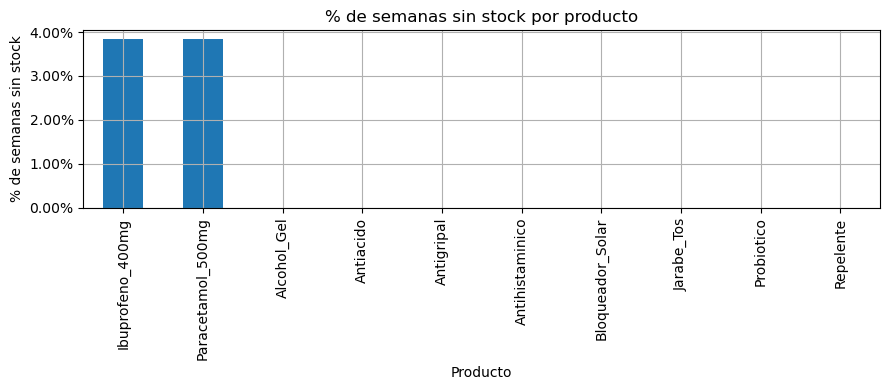

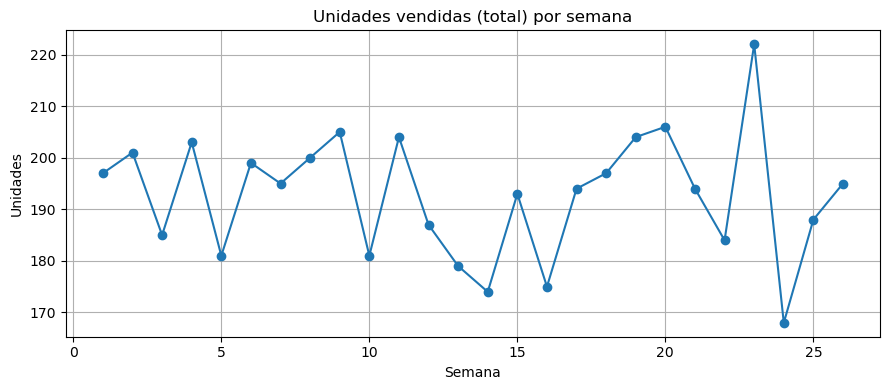

In [5]:
import matplotlib.ticker as mtick 
# --- Top productos por semanas sin stock --- 
# (renombra el indicador si quieres mantener consistencia en todo el notebook) 
df = df.rename(columns={"stockout_sem": "semana_sin_stock"}) 

top_sin_stock = ( 
    df.groupby("producto")["semana_sin_stock"]
        .mean() # proporción de semanas sin stock 
        .sort_values(ascending=False) 
        .head(10) 
)

# Muestra la serie (formato porcentaje opcional) 
display(top_sin_stock.rename("%_semanas_sin_stock").map(lambda 
x: f"{x*100:.2f}%")) 
ax = top_sin_stock.plot(kind="bar") 
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))  # 0.04 -> 4% 
plt.title("% de semanas sin stock por producto") 
plt.ylabel("% de semanas sin stock") 
plt.xlabel("Producto") 
plt.tight_layout()
plt.show()

# --- Tendencia de unidades vendidas por semana (total) --- 
serie_total = df.groupby("semana")["unidades_vendidas"].sum() 
ax = serie_total.plot(marker="o") 
plt.title("Unidades vendidas (total) por semana") 
plt.ylabel("Unidades") 
plt.xlabel("Semana") 
plt.tight_layout() 
plt.show() 

In [6]:
# === PREDICTIVA: tendencia lineal del total y (opcional) por producto ===

import numpy as np
import pandas as pd

# Total por semana
serie = df.groupby("semana")["unidades_vendidas"].sum().reset_index()

X = serie["semana"].to_numpy().reshape(-1, 1)
y = serie["unidades_vendidas"].to_numpy()

Xd = np.hstack([X, np.ones_like(X)])  # [semana, 1]
a, b = (np.linalg.pinv(Xd.T @ Xd) @ (Xd.T @ y)).tolist()  # mínimos cuadrados

next_week = int(serie["semana"].max() + 1)
y_next = a * next_week + b

print(f"Pronóstico TOTAL para la semana {next_week}: {y_next:.1f} unidades")

# (Opcional) por producto
prod = "Paracetamol_500mg"

s_prod = (
    df[df["producto"] == prod]
    .groupby("semana")["unidades_vendidas"]
    .sum()
    .reset_index()
)

if len(s_prod) >= 3:
    Xp = s_prod["semana"].to_numpy().reshape(-1, 1)
    yp = s_prod["unidades_vendidas"].to_numpy()

    Xpd = np.hstack([Xp, np.ones_like(Xp)])

    ap, bp = (np.linalg.pinv(Xpd.T @ Xpd) @ (Xpd.T @ yp)).tolist()

    y_next_prod = ap * next_week + bp

    print(
        f"{prod}: pronóstico para semana {next_week} = "
        f"{y_next_prod:.1f} unidades"
    )

# === PRESCRIPTIVA: alertas de reorden en la última semana observada ===

# Asegurar tasa_venta
if "tasa_venta" not in df.columns:
    df = df.copy()
    df["tasa_venta"] = (
        df["unidades_vendidas"]
        / df["stock_inicio_sem"].replace(0, np.nan)
    )

last_w = int(df["semana"].max())

base = df.loc[df["semana"] == last_w].copy()

base["tasa_venta"] = base.get(
    "tasa_venta",
    base["unidades_vendidas"] / base["stock_inicio_sem"].replace(0, np.nan)
)

# Pronóstico simple por producto = media de últimas 3 semanas
agg = df.groupby(
    ["producto", "semana"],
    as_index=False
)["unidades_vendidas"].sum()

hist3 = (
    agg.sort_values(["producto", "semana"])
    .groupby("producto", group_keys=False)
    .tail(3)
)

prom3 = (
    hist3.groupby("producto", as_index=False)["unidades_vendidas"]
    .mean()
    .rename(columns={"unidades_vendidas": "forecast_next"})
)

base = base.merge(prom3, on="producto", how="left")

base["forecast_next"] = (
    base["forecast_next"]
    .fillna(base["unidades_vendidas"])
    .clip(lower=1)
)

# Cobertura en semanas
base["cobertura_sem"] = (
    base["stock_fin_sem"] / base["forecast_next"]
).replace([np.inf, -np.inf], np.nan).fillna(999.0)

# Percentiles para lógica C
p25_stock = (
    df.groupby("producto")["stock_fin_sem"]
    .quantile(0.25)
    .rename("p25_stock")
)

p75_tasa = (
    df.groupby("producto")["tasa_venta"]
    .quantile(0.75)
    .rename("p75_tasa")
)

base = (
    base.merge(p25_stock, on="producto", how="left")
        .merge(p75_tasa, on="producto", how="left")
)

# Lógica A: umbrales simples (conservador)
UMBRAL_COBERTURA_A = 1.5
UMBRAL_LEADTIME_A = 4
UMBRAL_STOCK_BAJO = 30

base["alerta_A"] = (
    (base["cobertura_sem"] < UMBRAL_COBERTURA_A)
    | (base["stock_fin_sem"] <= UMBRAL_STOCK_BAJO)
    | (
        (base["tasa_venta"] > 0.50)
        & (base["lead_time_dias"] >= UMBRAL_LEADTIME_A)
    )
).astype(int)

# Lógica B: cobertura + lead time (recomendada)
UMBRAL_COBERTURA_B = 1.2
UMBRAL_LEADTIME_B = 5

base["alerta_B"] = (
    (base["cobertura_sem"] < UMBRAL_COBERTURA_B)
    & (base["lead_time_dias"] >= UMBRAL_LEADTIME_B)
).astype(int)

# Lógica C: percentiles (auto-calibrada)
base["alerta_C"] = (
    (
        base["stock_fin_sem"]
        <= base["p25_stock"].fillna(base["stock_fin_sem"].min())
    )
    | (
        (
            base["tasa_venta"]
            <= base["p75_tasa"].fillna(base["tasa_venta"].median())
        )
        & (base["lead_time_dias"] >= 5)
    )
).astype(int)

# Motivos y priorización
base["motivo_A"] = np.where(
    base["alerta_A"] == 1,
    "Cobertura/Stock bajo o Tasa+LT",
    ""
)

base["motivo_B"] = np.where(
    base["alerta_B"] == 1,
    "Cobertura<umbral & LeadTime",
    ""
)

base["motivo_C"] = np.where(
    base["alerta_C"] == 1,
    "Percentiles: stock bajo o tasa alta",
    ""
)

lead_max = max(1.0, float(base["lead_time_dias"].max()))
tasa_max = max(1e-9, float(base["tasa_venta"].max()))

inv_cov = 1.0 / np.maximum(base["cobertura_sem"], 0.1)

base["score_prioridad"] = (
    0.5 * inv_cov
    + 0.3 * (base["lead_time_dias"] / lead_max)
    + 0.2 * (base["tasa_venta"] / tasa_max)
)

cols = [
    "producto",
    "stock_fin_sem",
    "forecast_next",
    "cobertura_sem",
    "tasa_venta",
    "lead_time_dias",
    "alerta_A",
    "alerta_B",
    "alerta_C",
    "motivo_A",
    "motivo_B",
    "motivo_C",
    "score_prioridad",
]

tabla_alertas = (
    base[cols]
    .sort_values(
        ["alerta_B", "alerta_A", "alerta_C", "score_prioridad"],
        ascending=[False, False, False, False]
    )
    .reset_index(drop=True)
)

print(
    "Resumen de alertas (última semana): "
    f"A={int(base['alerta_A'].sum())} | "
    f"B={int(base['alerta_B'].sum())} | "
    f"C={int(base['alerta_C'].sum())}"
)

display(tabla_alertas.head(15))



Pronóstico TOTAL para la semana 27: 191.4 unidades
Paracetamol_500mg: pronóstico para semana 27 = 41.1 unidades
Resumen de alertas (última semana): A=1 | B=1 | C=6


,producto,stock_fin_sem,forecast_next,cobertura_sem,tasa_venta,lead_time_dias,alerta_A,alerta_B,alerta_C,motivo_A,motivo_B,motivo_C,score_prioridad
0,Ibuprofeno_400mg,32,29.000000,1.103448,0.448276,5,1,1,1,Cobertura/Stock bajo o Tasa+LT,Cobertura<umbral & LeadTime,Percentiles: stock bajo o tasa alta,0.903125
1,Paracetamol_500mg,61,35.666667,1.710280,0.445455,6,0,0,1,,,Percentiles: stock bajo o tasa alta,0.791091
2,Suero_Oral,71,15.333333,4.630435,0.183908,6,0,0,1,,,Percentiles: stock bajo o tasa alta,0.490033
3,Jarabe_Tos,70,13.000000,5.384615,0.125000,6,0,0,1,,,Percentiles: stock bajo o tasa alta,0.448626
4,Probiotico,31,8.333333,3.720000,0.225000,3,0,0,1,,,Percentiles: stock bajo o tasa alta,0.384793
5,Repelente,61,5.666667,10.764706,0.102941,5,0,0,1,,,Percentiles: stock bajo o tasa alta,0.342376
6,Antigripal,76,16.333333,4.653061,0.191489,4,0,0,0,,,,0.392890
7,Vitaminas_C,50,14.333333,3.488372,0.230769,2,0,0,0,,,,0.346292
8,Antiacido,59,12.666667,4.657895,0.180556,3,0,0,0,,,,0.337900
9,Alcohol_Gel,89,12.666667,7.026316,0.118812,2,0,0,0,,,,0.224169
